# Which of my sites are most at risk?

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/RiskThinking/crc-docs/blob/main/notebooks/which_sites_are_most_at_risk.ipynb)

**The question:** *"We run ten warehouses across North America. Which ones face
the biggest climate change, and from what?"*

One site at a time is easy. A **portfolio** needs every site measured the same
way, so they can be ranked. We answer three times, each with a better data
source, using the same open toolkit, [crc-sdk](https://github.com/RiskThinking/crc-sdk):

| | Data | What it can tell you |
|---|---|---|
| **A** | ERA5, the free global weather record (reanalysis) | Which sites had the harshest past, on a coarse grid |
| **B** | **CRC Open**: free, ready-made climate curves | How each site changes by 2070–2080 under a high-emissions future, for 63 hazards (SSP5-8.5; [other futures on request](mailto:sales@riskthinking.ai)) |
| **C** | **CDT**, Riskthinking.AI's Climate Digital Twin (enterprise) | The same against a historical baseline, for every emissions future |

Run it on Colab with **Runtime → Run all**; no account needed for A and B.
Replace `SITES` with your own list (a name, latitude and longitude per site).

## Setup

In [1]:
#@title Install packages (Colab) and list your sites
import importlib.util
import os
import subprocess
import sys

IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("crc_sdk") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "--quiet",
        "crc-sdk[zarr,netcdf,geometry]>=0.11.1,<1", "plotly>=6,<7", "velo-sdk",
    ])

import pandas as pd

# An example portfolio: ten warehouses. Any list of names and coordinates works.
SITES = pd.DataFrame([
    ("Phoenix", 33.45, -112.07), ("Los Angeles", 34.05, -118.24), ("Seattle", 47.61, -122.33),
    ("Denver", 39.74, -104.99), ("Houston", 29.76, -95.37), ("Chicago", 41.88, -87.63),
    ("Atlanta", 33.75, -84.39), ("Miami", 25.77, -80.19), ("Toronto", 43.65, -79.38),
    ("New York", 40.71, -74.00),
], columns=["site", "latitude", "longitude"])

# Small, quick runs for continuous integration; the same code runs either way.
CI = os.environ.get("CRC_DOCS_CI") == "1"
ERA5_YEARS = (2018, 2021) if CI else (2002, 2021)   # about 15 seconds per year per hazard
EARLY, LATE = (2025, 2030, 2035), (2070, 2075, 2080)

In [2]:
import warnings
from pathlib import Path

import numpy as np
import plotly.graph_objects as go
import plotly.io as pio
import pyarrow as pa
import pyarrow.compute as pc
import pyarrow.parquet as pq

from crc_sdk.fitting import fit_distribution
from crc_sdk.workflows import BlockExtremaPolicy, HazardDataset, curve_parameters_from_row

# Interactive charts when you run it; saved images so GitHub can show them too.
STATIC_PREVIEW = os.environ.get("CRC_NOTEBOOK_STATIC_PREVIEW") == "1"
pio.renderers.default = (
    "colab" if IN_COLAB else "plotly_mimetype+png" if STATIC_PREVIEW else "plotly_mimetype"
)
pio.templates.default = "plotly_white"

DATA = Path("data") / "sites"
DATA.mkdir(parents=True, exist_ok=True)

INK, BLUE, ORANGE = "#52514e", "#2a78d6", "#eb6834"
CDT_COLORS = {"historic": "#52514e", "ssp126": "#2a78d6", "ssp245": "#1baf7a", "ssp585": "#eb6834"}
FONT = dict(family="Inter, Helvetica, Arial, sans-serif", size=14)


def one_in(distribution, rp):
    return float(np.asarray(distribution.quantiles([1 - 1 / rp]))[0])


def layout(fig, title, **kwargs):
    fig.update_layout(title=dict(text=title, x=0.01), font=FONT, height=460,
                      margin=dict(l=110, r=30, t=70, b=60), **kwargs)
    return fig

## A. Ask the weather record

[ERA5](https://cds.climate.copernicus.eu/datasets/reanalysis-era5-single-levels)
is the free global weather record (CC BY 4.0). crc-sdk reads a public copy and
keeps each year's **hottest day** and **wettest day** on a grid that covers all
the sites at once; we then fit a curve at the grid point nearest each site and
read its **1-in-10-year** value (a level with a 10% chance in any year).

In [3]:
bounds = (SITES["longitude"].min() - 2, SITES["latitude"].min() - 2,
          SITES["longitude"].max() + 2, SITES["latitude"].max() + 2)


def era5_one_in_ten(recipe):
    plan = (
        HazardDataset.era5(recipe, store="wb2-1p5")
        .for_area(bounds)
        .years(*ERA5_YEARS)
        .cache(DATA / "era5", mode="reuse")
        .canonicalize(policy=BlockExtremaPolicy.curated(h3_resolution=3, minimum_years=4))
    )
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        annual = plan.annual_extremes().to_pandas().dropna(subset=["value"])
    points = annual.groupby(["latitude", "longitude"])
    grid = np.array(list(points.groups))
    values = []
    for _, site in SITES.iterrows():
        nearest = grid[np.argmin(np.hypot(grid[:, 0] - site["latitude"], grid[:, 1] - site["longitude"]))]
        record = points.get_group(tuple(nearest))["value"].to_numpy()
        values.append(one_in(fit_distribution(record, "genextreme", method="lmoments").distribution, 10))
    return values


past = SITES[["site"]].copy()
past["hottest day °C"] = np.round(era5_one_in_ten("txx"), 1)
past["wettest day mm"] = np.round(era5_one_in_ten("rx1day"), 0)
past.sort_values("hottest day °C", ascending=False).reset_index(drop=True)

,site,hottest day °C,wettest day mm
0,Phoenix,46.5,32.0
1,Houston,40.1,95.0
2,Los Angeles,36.4,48.0
3,Atlanta,36.0,73.0
4,Denver,33.6,36.0
5,Chicago,32.5,53.0
6,Toronto,32.1,47.0
7,New York,31.6,77.0
8,Miami,30.5,90.0
9,Seattle,29.0,68.0


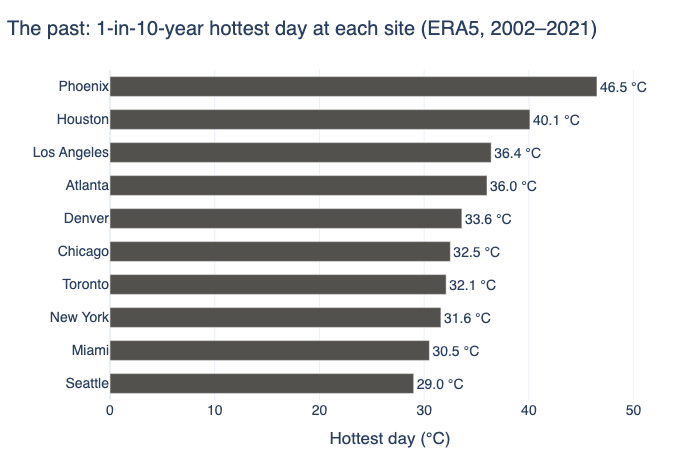

In [4]:
order = past.sort_values("hottest day °C")
fig = go.Figure(go.Bar(
    y=order["site"], x=order["hottest day °C"], orientation="h", marker_color=INK, width=0.6,
    text=[f"{v:.1f} °C" for v in order["hottest day °C"]], textposition="outside", cliponaxis=False,
    hovertemplate="%{y}: %{x:.1f} °C<extra></extra>",
))
layout(fig, f"The past: 1-in-10-year hottest day at each site (ERA5, {ERA5_YEARS[0]}–{ERA5_YEARS[1]})",
       xaxis=dict(title="Hottest day (°C)", range=[0, order["hottest day °C"].max() * 1.15]), showlegend=False)
fig.show()

**What A tells us, and what it can't:**

- ✅ Free, global and consistent: every site is measured the same way.
- ❌ **Only the past.** It ranks the sites as they *were*, not as they will be.
- ❌ **Blurry.** Each grid cell is about 165 km wide; nearby sites can share one.
- ❌ **A few hazards, by hand.** Each extra hazard is another download and fit.

## B. Ask CRC Open

[CRC Open](https://github.com/RiskThinking/crc-sdk/blob/main/docs/sources/crc-open.md)
has ready-made curves for 63 hazards worldwide, 2025–2100, on hexagons of about
250 km² ([CC BY-NC 4.0](https://creativecommons.org/licenses/by-nc/4.0/)). A
short loop evaluates **every site against every hazard** into one table. Here
we take four: hottest day, wettest day, number of hot days and wildfire weather
(Fire Weather Index), and compare 2025–2035 with 2070–2080 (each averaged over
three horizons, because single horizons wobble).

This public release covers one high-emissions future, SSP5-8.5. Lower-emissions
futures are available too: [contact sales](mailto:sales@riskthinking.ai).

In [5]:
HAZARDS = {"tx_max": "Hottest day (°C)", "rx1day": "Wettest day (mm)",
           "hot_days": "Hot days (count)", "fwi": "Wildfire weather (FWI)"}
assets = pa.table({"asset_id": SITES["site"], "longitude": SITES["longitude"], "latitude": SITES["latitude"]})

records = []
for _, site in SITES.iterrows():
    one = assets.filter(pc.equal(assets["asset_id"], site["site"]))
    for hazard in HAZARDS:
        plan = (
            HazardDataset.crc_open()
            .for_area((site["longitude"] - 0.05, site["latitude"] - 0.05,
                       site["longitude"] + 0.05, site["latitude"] + 0.05))
            .hazards([hazard])
            .horizons(list(EARLY + LATE))
            .cache(DATA / "crc-open", mode="reuse")
        )
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            plan.for_assets(one).return_periods([10]).write_parquet(DATA / "site.parquet")
        records += pq.read_table(DATA / "site.parquet").to_pylist()

evaluated = pd.DataFrame(records)
evaluated["window"] = np.where(evaluated["horizon"].isin(EARLY), "early", "late")
evaluated.loc[evaluated["hazard_name"] == "tx_max", "value_rp10"] -= 273.15   # kelvin to °C
windows = evaluated.pivot_table(index=["asset_id", "hazard_name"], columns="window", values="value_rp10").reset_index()
windows["change"] = windows["late"] - windows["early"]
print(f"{len(evaluated)} site × hazard × horizon values from one table")
windows.pivot(index="asset_id", columns="hazard_name", values="change").round(1)

240 site × hazard × horizon values from one table


hazard_name,fwi,hot_days,rx1day,tx_max
asset_id,,,,
Atlanta,4.3,47.1,19.5,3.6
Chicago,6.4,26.5,10.0,3.9
Denver,7.4,63.9,4.4,3.7
Houston,6.0,62.7,13.1,2.3
Los Angeles,2.0,47.2,15.6,2.4
Miami,1.2,49.1,10.9,2.5
New York,4.1,48.3,-1.1,3.9
Phoenix,4.4,94.5,12.0,2.9
Seattle,4.9,40.4,3.7,3.9


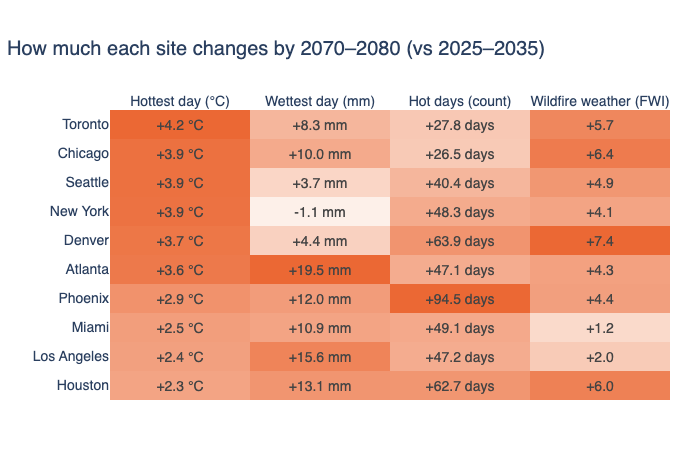

In [6]:
change = windows.pivot(index="asset_id", columns="hazard_name", values="change")[list(HAZARDS)]
change = change.loc[change["tx_max"].sort_values().index]
units = {"tx_max": " °C", "rx1day": " mm", "hot_days": " days", "fwi": ""}
# Colour shows each column's change relative to its largest change, so hazards with different units compare.
relative = change / change.abs().max()
fig = go.Figure(go.Heatmap(
    z=relative.to_numpy(), x=list(HAZARDS.values()), y=change.index, colorscale=[[0, "#fdf0e9"], [1, ORANGE]],
    zmin=0, zmax=1, showscale=False,
    text=[[f"{v:+.1f}{units[h]}" for h, v in row.items()] for _, row in change.iterrows()],
    texttemplate="%{text}", hovertemplate="%{y}, %{x}: %{text}<extra></extra>",
))
layout(fig, "How much each site changes by 2070–2080 (vs 2025–2035)",
       xaxis=dict(side="top"), yaxis_title=None)
fig.update_layout(margin=dict(t=110))
fig.show()

Read across a row to see a site's whole profile; read down a column to see which
site changes most for that hazard. Darker means a bigger change *within that
column*.

> 💡 **Key idea: today's ranking is not tomorrow's.** Being hot already and
> getting hotter are different things. In the chart below each line runs from a
> site's hottest day in 2025–2035 (grey dot) to 2070–2080 (orange dot), sorted
> by how far it moves. A place that is mild today can warm the most, which a
> ranking of the past (A) would never reveal.

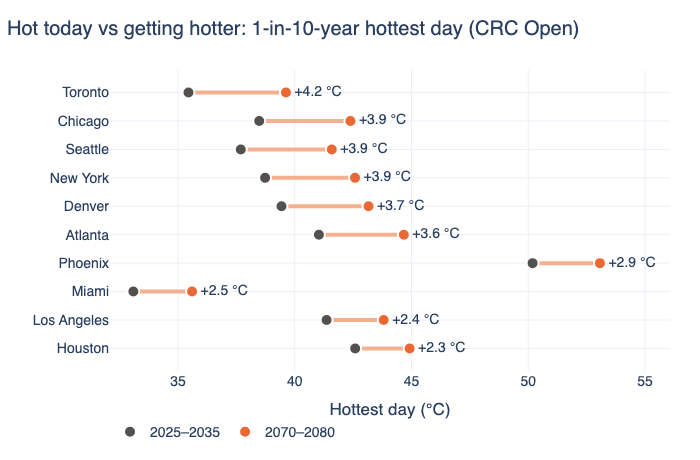

In [7]:
heat = windows[windows["hazard_name"] == "tx_max"].set_index("asset_id").sort_values("change")
fig = go.Figure()
for site, row in heat.iterrows():
    fig.add_trace(go.Scatter(x=[row["early"], row["late"]], y=[site, site], mode="lines",
                             line=dict(color="#f5b08f", width=4), showlegend=False, hoverinfo="skip"))
fig.add_trace(go.Scatter(x=heat["early"], y=heat.index, mode="markers", name="2025–2035",
                         marker=dict(size=12, color=INK, line=dict(width=2, color="white")),
                         hovertemplate="%{y}: %{x:.1f} °C in 2025–2035<extra></extra>"))
fig.add_trace(go.Scatter(x=heat["late"], y=heat.index, mode="markers+text", name="2070–2080",
                         text=[f"+{c:.1f} °C" for c in heat["change"]], textposition="middle right",
                         marker=dict(size=12, color=ORANGE, line=dict(width=2, color="white")),
                         hovertemplate="%{y}: %{x:.1f} °C in 2070–2080<extra></extra>"))
layout(fig, "Hot today vs getting hotter: 1-in-10-year hottest day (CRC Open)",
       xaxis=dict(title="Hottest day (°C)", range=[heat["early"].min() - 1, heat["late"].max() + 3]),
       legend=dict(orientation="h", y=-0.15))
fig.show()

**What B adds over A:** the future, finer detail, and many hazards with the same
code, in one table, ready to rank, filter or feed into your own damage functions.

**What B leaves out:** one emissions pathway (SSP5-8.5) and no historical
baseline from the same models. Need other pathways or a baseline for planning
or disclosure? [Contact our sales team](mailto:sales@riskthinking.ai).

## C. Ask CDT

**CDT** (Climate Digital Twin) is Riskthinking.AI's enterprise service. For every
site it returns a **historical baseline** (around 2010) and values for **every
emissions pathway**, so "how much worse" compares like with like. Here: the
1-in-10-year hottest day and number of hot days, historical vs 2070–2090
(averaged) under three futures.

CDT also turns hazards into **financial impact** for buildings and already maps
the assets of thousands of companies and market indexes.

The saved results below come from a CDT run: a small table and one chart. To run
it yourself you need an API key; [start a CDT Express trial](https://velo.riskthinking.ai/cdt-express)
to get one. In Colab, store it as a secret named `RISKTHINKING_API_KEY`. Without a
key the cells explain how to get one and skip.

Prefer chatting to coding? Connect the [CDT Express MCP server](https://github.com/RiskThinking/cdt-express-mcp)
to Claude or ChatGPT and ask: *"Which of these ten cities gets the most extra hot days by 2080?"*

In [8]:
api_key = os.environ.get("RISKTHINKING_API_KEY")
if api_key is None and IN_COLAB:
    from google.colab import userdata
    try:
        api_key = userdata.get("RISKTHINKING_API_KEY")
    except Exception:
        api_key = None

cdt = None
if api_key:
    from velo_sdk.api import APIClient

    client = APIClient(api_key=api_key)
    requests = [("historic", 2010)] + [(p, h) for p in ("ssp126", "ssp245", "ssp585") for h in (2070, 2080, 2090)]
    records = []
    for _, site in SITES.iterrows():
        for pathway, horizon in requests:
            response = client.get("/v4/climate/metrics/exposure", params={
                "latitude": site["latitude"], "longitude": site["longitude"], "risk_factor": "tx_max,hot_days",
                "pathway": pathway, "horizon": str(horizon), "return_periods": "10",
            })
            for result in response["results"]:
                if result["index_name"] in ("tx_max", "hot_days"):
                    value = float(result["exposure_return_periods"]["10"])
                    records.append({"site": site["site"], "hazard": result["index_name"], "pathway": pathway,
                                    "value": value - 273.15 if result["index_name"] == "tx_max" else value})
    cdt = pd.DataFrame(records).groupby(["site", "hazard", "pathway"], as_index=False)["value"].mean()
    display(cdt.pivot_table(index="site", columns=["hazard", "pathway"], values="value").round(1))
else:
    print("No RISKTHINKING_API_KEY found, so section C is skipped.")
    print("Start a trial at https://velo.riskthinking.ai/cdt-express, or contact sales@riskthinking.ai.")

hazard      hot_days                        tx_max                     
pathway     historic ssp126 ssp245 ssp585 historic ssp126 ssp245 ssp585
site                                                                   
Atlanta         35.0   50.3   64.0   72.0     37.8   40.3   42.4   44.7
Chicago         17.0   24.7   33.0   42.0     34.5   37.4   39.7   42.4
Denver          23.0   74.0   91.7   98.3     36.2   38.3   41.0   43.3
Houston         40.0   75.7   85.0   93.0     39.4   42.3   44.2   45.4
Los Angeles     31.0   52.3   62.3   77.0     41.0   41.5   42.7   44.4
Miami           29.0   50.3   73.3   79.0     31.9   33.3   34.2   36.1
New York        19.0   56.7   65.7   69.0     36.7   38.7   40.4   42.9
Phoenix         39.0  107.0  115.3  135.7     47.2   49.2   51.5   53.4
Seattle          8.0   36.3   53.3   60.7     33.6   36.1   38.6   41.5
Toronto          3.0   27.7   39.0   43.7     31.7   35.0   37.2   40.1

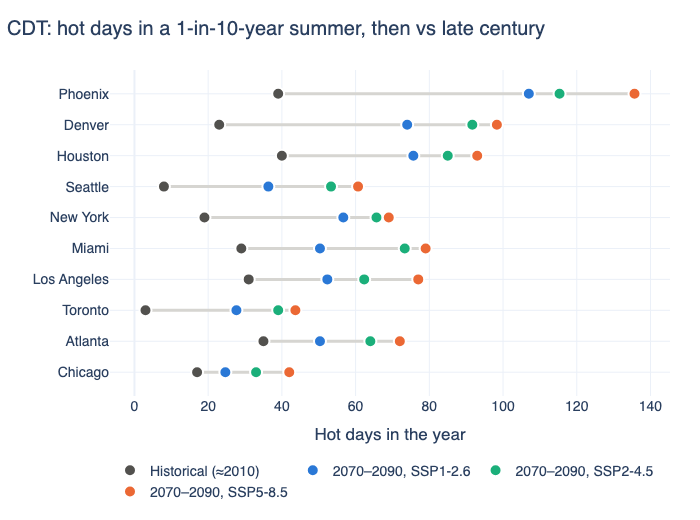

Most extra hot days under SSP5-8.5: Phoenix (+97), then Denver (+75); fewest: Chicago (+25).


In [9]:
if cdt is not None:
    hot = cdt[cdt["hazard"] == "hot_days"].pivot(index="site", columns="pathway", values="value")
    hot = hot.loc[(hot["ssp585"] - hot["historic"]).sort_values().index]
    labels = {"historic": "Historical (≈2010)", "ssp126": "2070–2090, SSP1-2.6",
              "ssp245": "2070–2090, SSP2-4.5", "ssp585": "2070–2090, SSP5-8.5"}
    fig = go.Figure()
    for site in hot.index:
        fig.add_trace(go.Scatter(x=[hot.loc[site].min(), hot.loc[site].max()], y=[site, site], mode="lines",
                                 line=dict(color="#d6d5d1", width=3), showlegend=False, hoverinfo="skip"))
    for pathway, color in CDT_COLORS.items():
        fig.add_trace(go.Scatter(x=hot[pathway], y=hot.index, mode="markers", name=labels[pathway],
                                 marker=dict(size=12, color=color, line=dict(width=2, color="white")),
                                 hovertemplate="%{y}: %{x:.0f} hot days<extra></extra>"))
    layout(fig, "CDT: hot days in a 1-in-10-year summer, then vs late century",
           xaxis_title="Hot days in the year", legend=dict(orientation="h", y=-0.18))
    fig.update_layout(height=520)
    fig.show()
    gain = (hot["ssp585"] - hot["historic"]).sort_values(ascending=False)
    print(f"Most extra hot days under SSP5-8.5: {gain.index[0]} (+{gain.iloc[0]:.0f}), "
          f"then {gain.index[1]} (+{gain.iloc[1]:.0f}); fewest: {gain.index[-1]} (+{gain.iloc[-1]:.0f}).")

**What C adds over B:**

- **A matching historical baseline**, so each site's change is measured from the
  same models, not stitched from two sources.
- **Every pathway**: show how much a lower-emissions world spares each site.
- **Financial impact and company data**: damage to buildings in money terms,
  and ready-made portfolios for thousands of companies and market indexes.

## Recap

| | A. ERA5 | B. CRC Open | C. CDT |
|---|---|---|---|
| Ranks sites by | The past | Change to 2070–2080 | Change from a historical baseline |
| Hazards | A few, fitted by hand | 63, same code for each | 60+, one request |
| Emissions pathways | ❌ | SSP5-8.5 ([others on request](mailto:sales@riskthinking.ai)) | All, plus warming levels |
| Detail | ~165 km cells | ~250 km² hexagons | ~250 km² hexagons |
| Financial impact | ❌ | Bring your own damage function | ✅ built in |
| Cost | Free | Free (non-commercial) | [Trial](https://velo.riskthinking.ai/cdt-express), then licence |

**Next steps:** paste your own `SITES` and run again; run the same screening
headlessly on a CSV with
[`pipelines/which_sites_are_most_at_risk.py`](https://github.com/RiskThinking/crc-docs/blob/main/pipelines/which_sites_are_most_at_risk.py);
or ask an AI assistant with the [site-ranking skill](https://github.com/RiskThinking/crc-docs/blob/main/.agents/skills/which-sites-are-most-at-risk/SKILL.md).

*Data: ERA5 by Copernicus Climate Change Service (CC BY 4.0), via the WeatherBench 2 copy;
CRC Open by Riskthinking.AI (CC BY-NC 4.0); CDT by Riskthinking.AI (licensed).*